In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "04"

# 04 · Condition 1: it must stay stable on every grid

**Question:** a controller tuned for a stiff grid, does it still work on a weak grid?

**Setup.** This notebook is **analysis**, not HIL measurement: the sampled-data model of the filter,
the one-sample computation delay and the controller (`hil_bench/pr_design.py`), checked on grids from
stiff to SCR 3. The HIL runs confirm the chosen design ran stably on all four grids; they do not measure
the margins.

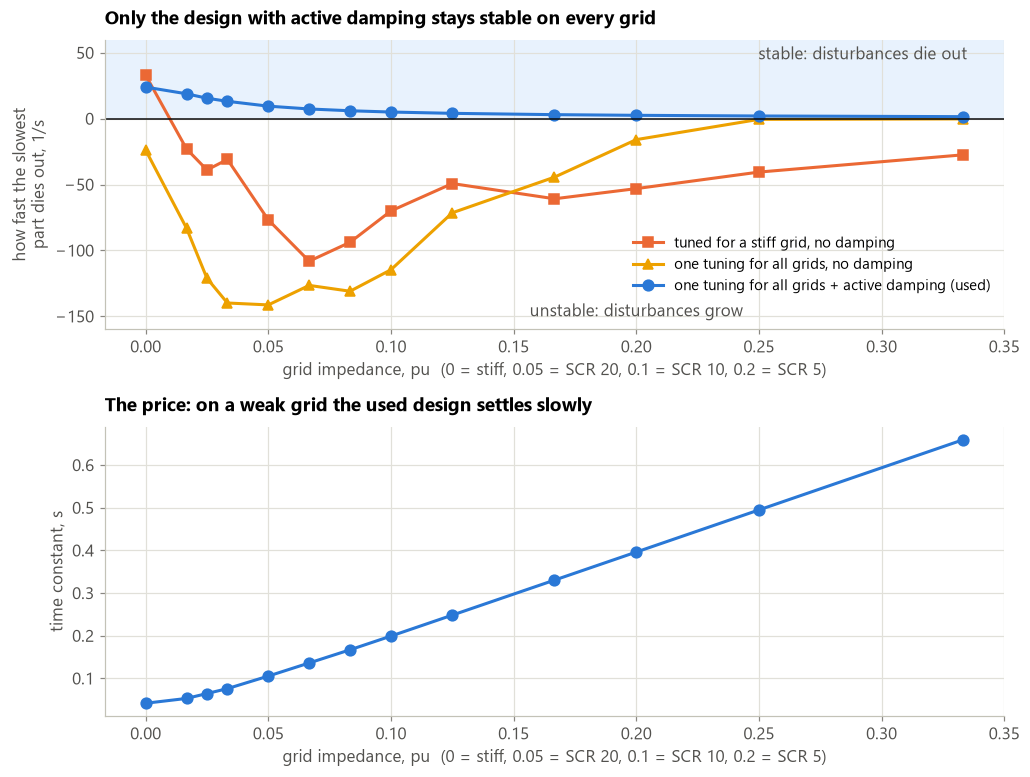

In [2]:
scrs = [None, 60, 40, 30, 20, 15, 12, 10, 8, 6, 5, 4, 3]
designs = {"tuned for a stiff grid, no damping": (D.design(), A.OTHER, "s"),
           "one tuning for all grids, no damping": (D.robust(kc=0.0, kp=1.5, sigma=50), "#eda100", "^"),
           "one tuning for all grids + active damping (used)": (D.robust(kc=2.0, kp=1.5, sigma=50), A.USED, "o")}
rows = []
for name, (d, c, m) in designs.items():
    for s in scrs:
        r = D.radius(d, *D.scr_rl(s))
        rows.append({"design": name, "SCR": np.inf if s is None else s, "Zgrid_pu": 0 if s is None else 1 / s,
                     "decay_per_s": -np.log(r) / P.TS})
st = pd.DataFrame(rows)
fig, ax = A.panels(2, h=3.6)
for name, (d, c, m) in designs.items():
    x = st[st.design == name]
    ax[0].plot(x.Zgrid_pu, x.decay_per_s, m + "-", color=c, label=name)
ax[0].axhspan(0, 60, color="#e8f2fd", zorder=0); ax[0].axhline(0, color="#0b0b0b", lw=1)
ax[0].set_ylim(-160, 60)
ax[0].text(0.335, 45, "stable: disturbances die out", ha="right", color=A.INK2)
ax[0].text(0.2, -150, "unstable: disturbances grow", ha="center", color=A.INK2)
ax[0].set_xlabel("grid impedance, pu  (0 = stiff, 0.05 = SCR 20, 0.1 = SCR 10, 0.2 = SCR 5)")
ax[0].set_ylabel("how fast the slowest\npart dies out, 1/s")
ax[0].set_title("Only the design with active damping stays stable on every grid")
ax[0].legend(loc="lower right", bbox_to_anchor=(1.0, 0.08), fontsize=9.5)
x = st[st.design.str.contains("used")]
ax[1].plot(x.Zgrid_pu, 1 / x.decay_per_s, "o-", color=A.USED)
ax[1].set_xlabel("grid impedance, pu  (0 = stiff, 0.05 = SCR 20, 0.1 = SCR 10, 0.2 = SCR 5)")
ax[1].set_ylabel("time constant, s")
ax[1].set_title("The price: on a weak grid the used design settles slowly")
A.save(fig, "04_stability", st)
used = st[st.design.str.contains("used")]
slow = used[used.SCR == 5].decay_per_s.iloc[0]
claim("C4.1", "Controller tuned for a stiff grid without damping is unstable as soon as the grid has impedance",
      "unstable from SCR 60 down", "analysis, hil_bench/pr_design.py")
claim("C4.2", "Used design (one tuning + active damping, Kc = 2 Ω) is stable from stiff to SCR 3; slowest mode at SCR 5 decays at",
      "%.1f 1/s (time constant %.2f s)" % (slow, 1 / slow), "analysis, hil_bench/pr_design.py; ran stably on HIL404 on all grids")

**Reading.** The y-axis says how quickly a disturbance dies out. Above zero it dies out (stable), below
zero it grows (unstable).

- **Orange squares**: the usual way, tuned on a stiff grid. Fine on a stiff grid, unstable as soon as
  there is any grid impedance. The filter resonance has moved down into the 17th-21st orders
  (notebook 01), right where the controller has high gain.
- **Yellow triangles**: one tuning for all grids, but no damping. Still unstable.
- **Blue circles**: one tuning for all grids **plus active damping**. Stable everywhere. The price is
  speed (bottom panel): the slowest part has a time constant of about 0.4 s on SCR 5, instead of tens of
  milliseconds on a stiff grid.
  That is why the inverter needs time to settle after a step (notebook 06).

## Why one tuning can work for all grids

Each resonant term needs to know roughly the phase of the plant at its frequency. That phase changes with
the grid. Active damping makes the change smaller, so a single middle value is close enough everywhere.

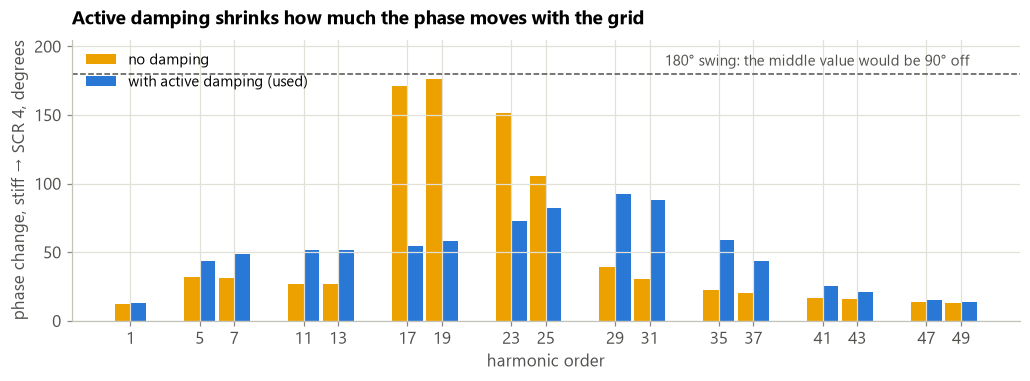

In [3]:
dn = D.robust(kc=0.0, kp=1.5, sigma=50); dd = D.robust(kc=2.0, kp=1.5, sigma=50)
h = np.array(dd["hs"])
fig, ax = A.panels(1, h=3.6)
ax[0].bar(h - 0.45, dn["spread_deg"], 0.9, color="#eda100", label="no damping")
ax[0].bar(h + 0.45, dd["spread_deg"], 0.9, color=A.USED, label="with active damping (used)")
ax[0].axhline(180, color=A.LIMIT, ls="--", lw=1); ax[0].set_ylim(0, 205)
ax[0].text(49.5, 186, "180° swing: the middle value would be 90° off", ha="right", color=A.INK2, fontsize=9.5)
A.orders_axis(ax[0], list(h)); ax[0].set_ylabel("phase change, stiff → SCR 4, degrees")
ax[0].set_title("Active damping shrinks how much the phase moves with the grid")
ax[0].legend(loc="upper left")
sp = pd.DataFrame({"order": h, "spread_no_damping_deg": dn["spread_deg"], "spread_with_damping_deg": dd["spread_deg"]})
A.save(fig, "04_phase_spread", sp)
claim("C4.3", "With active damping, the largest phase change of any order between stiff grid and SCR 4",
      "%.0f° (so the middle value is at most %.0f° off)" % (max(dd["spread_deg"]), max(dd["spread_deg"]) / 2), "analysis, hil_bench/pr_design.py")

**Reading.** A resonant term still works if its phase guess is within about 90° of the truth. With
damping, the largest swing is about 93°, so the middle value is never more than about 46° off: safe on
every grid without knowing which one it is on. Without damping, the 17th-23rd orders (around the filter
resonance) swing by up to about 175°, so no single value works there. Damping makes some higher orders
swing a bit more, but all stay below about 93°.

## Limits of this notebook
- Linear model with ideal sampling. Nonlinear effects (PWM, saturation) are not in it.
- Grid is R-L with X/R = 3. A grid with capacitance (cables) is not covered.

In [4]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C4.1 | Controller tuned for a stiff grid without damping is unstable as soon as the grid has impedance | unstable from SCR 60 down | analysis, hil_bench/pr_design.py |
| C4.2 | Used design (one tuning + active damping, Kc = 2 Ω) is stable from stiff to SCR 3; slowest mode at SCR 5 decays at | 2.5 1/s (time constant 0.40 s) | analysis, hil_bench/pr_design.py; ran stably on HIL404 on all grids |
| C4.3 | With active damping, the largest phase change of any order between stiff grid and SCR 4 | 93° (so the middle value is at most 46° off) | analysis, hil_bench/pr_design.py |